<a href="https://colab.research.google.com/github/nadatabai/AquaSense-Tunisia/blob/main/AquaSense-Tunisia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AquaSense Tunisia



# 1. Introduction

## 1.1 Background and Context

Water scarcity is one of the major environmental and agricultural challenges facing many countries around the world. This issue is particularly important in Tunisia, where agriculture is highly dependent on climatic conditions, especially rainfall and water availability.

Climate change, rising temperatures, irregular precipitation patterns, and prolonged drought periods increase pressure on agricultural water resources. These conditions can negatively affect crop growth, agricultural productivity, and food security.

One of the main challenges in agriculture is identifying and anticipating water stress before it causes significant damage to crops. Traditional monitoring methods often depend on field observations and periodic measurements, which may not provide sufficient information for early detection and large-scale monitoring.

Recent developments in Artificial Intelligence (AI), Machine Learning (ML), and remote sensing offer new opportunities to address these challenges. By analyzing historical climate records, satellite observations, and environmental variables, intelligent systems can identify patterns, monitor environmental changes, and predict potential drought and water-stress conditions.

## 1.2 Problem Statement

In Tunisia, agricultural water management remains challenging due to the irregular distribution of rainfall, increasing temperatures, and limited water resources.

Farmers and agricultural decision-makers need reliable information to understand changing climatic conditions and anticipate periods of water scarcity.

However, several difficulties remain:

- Limited access to continuous and reliable agricultural monitoring data.
- Difficulty in identifying drought patterns early.
- Increasing variability in rainfall and temperature.
- Limited use of predictive analytical tools in agricultural decision-making.
- Difficulty in combining different environmental data sources to obtain meaningful insights.

Therefore, there is a need for an intelligent, data-driven system capable of analyzing environmental conditions and predicting potential agricultural water-stress risks.

## 1.3 Project Motivation

The motivation behind AquaSense Tunisia is to explore how Artificial Intelligence and Data Science can contribute to more sustainable agricultural water management.

Rather than relying only on historical observations, this project aims to use predictive models to identify environmental patterns and anticipate future conditions.

The project focuses on Tunisia because of its vulnerability to water scarcity and the importance of agriculture to its economy and food security.

By combining climate data, satellite observations, and Machine Learning techniques, AquaSense aims to transform raw environmental data into useful information that can support agricultural monitoring and decision-making.

## 1.4 Project Objectives

The main objective of AquaSense Tunisia is to develop an AI-based system for monitoring and predicting agricultural water-stress risks.

The specific objectives are:

1. **Climate Data Collection:** Collect historical meteorological data, including temperature, precipitation, relative humidity, and wind speed.

2. **Data Integration:** Combine different environmental datasets, including meteorological and satellite observations.

3. **Exploratory Data Analysis:** Identify climatic trends, seasonal variations, correlations, and potential drought patterns.

4. **Drought Indicator Development:** Calculate the Standardized Precipitation Index (SPI) to characterize meteorological drought conditions.

5. **Predictive Modeling:** Develop and compare Machine Learning and Deep Learning models to predict future drought-related risks.

6. **Model Evaluation:** Evaluate predictive performance using appropriate statistical metrics.

7. **Decision Support:** Develop an interactive dashboard to visualize environmental indicators, predictions, and risk levels.

## 1.5 Proposed Approach

The project follows a structured Data Science and Artificial Intelligence workflow.

First, historical meteorological data will be collected from reliable open-data sources such as NASA POWER and CHIRPS.

Next, the collected data will undergo preprocessing, cleaning, and exploratory analysis to identify missing values, seasonal patterns, and relationships between environmental variables.

Afterwards, drought indicators such as SPI will be calculated to characterize precipitation anomalies.

Several predictive models, including Random Forest, XGBoost, and Long Short-Term Memory (LSTM) networks, will then be developed and compared.

Finally, the results will be integrated into an interactive dashboard to facilitate the visualization and interpretation of predictions.

## 1.6 Expected Outcomes

At the end of the project, AquaSense Tunisia is expected to provide:

- A structured historical climate dataset for the selected study area.
- An analysis of climatic trends and precipitation variability.
- A drought-monitoring approach based on scientific indicators.
- Predictive models for future drought-related conditions.
- A comparative evaluation of Machine Learning and Deep Learning algorithms.
- An interactive dashboard for environmental data visualization.

The project will also provide an opportunity to investigate the potential and limitations of AI-based approaches in agricultural water management.

## 1.7 Project Scope

The initial implementation will focus on Kairouan, Tunisia, as a pilot study area.

The first development phase will concentrate on meteorological drought prediction using historical climate data.

In subsequent phases, satellite-derived indicators and additional environmental variables will be integrated to improve the assessment of agricultural water-stress risks.

It is important to distinguish meteorological drought from actual crop water stress. Predicting crop-level stress requires additional information, such as vegetation indicators, soil moisture, crop characteristics, and field observations.

Therefore, the project will progressively expand from meteorological drought analysis toward a more comprehensive agricultural water-stress monitoring system.

# 2. Libraries Installation and Import

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn requests

In [3]:
import os
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "reports"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project structure created successfully!")

Project structure created successfully!


# 3. Data Collection

Data collection is a fundamental step in the development of AquaSense Tunisia. The quality and reliability of the collected data directly influence the performance of the predictive models.

In this project, historical meteorological data will be collected to analyze climatic conditions and investigate drought-related patterns in Kairouan, Tunisia.

The collected dataset includes daily measurements of temperature, relative humidity, precipitation, and wind speed over a 25-year period (2001–2025).

The data will be obtained from NASA POWER, an open-access database providing meteorological and solar-related information for research and agricultural applications.

## 3.1 Study Area

The initial study area selected for AquaSense Tunisia is Kairouan, located in central Tunisia.

Kairouan is an important agricultural region characterized by a semi-arid climate, relatively low and irregular rainfall, and high temperatures during summer.

These climatic conditions make the region relevant for studying precipitation variability, drought patterns, and agricultural water management.

The geographical coordinates used to retrieve meteorological data are:

- **Latitude:** 35.6781° N
- **Longitude:** 10.0963° E
- **Country:** Tunisia

Kairouan will serve as the pilot study area for the initial development and evaluation of the proposed predictive system.

## 3.2 Data Source

The primary data source used in this project is NASA POWER (Prediction of Worldwide Energy Resources).

NASA POWER is an open-access platform developed by NASA that provides meteorological and solar-related datasets for different geographical locations worldwide.

It offers historical environmental observations and estimates that can be used in agricultural, climatic, and environmental studies.

For AquaSense Tunisia, the NASA POWER Daily API will be used to retrieve meteorological variables at the selected geographical coordinates.

**Data source:** NASA POWER

**API:** Daily Point API

**Community:** AG (Agroclimatology)

**Temporal Resolution:** Daily

**Study Period:** January 2001 – December 2025

**Official website:** https://power.larc.nasa.gov/

The selected variables will help us investigate the relationships between temperature, precipitation, humidity, and wind speed.

## 3.3 Data Acquisition

Meteorological data are collected using the NASA POWER API through Python.

The API request specifies the geographical coordinates, observation period, selected meteorological parameters, and data format.

The returned JSON response is transformed into a Pandas DataFrame to facilitate further processing and analysis.

The dataset is then exported as a CSV file and stored in the project's raw data directory.

The following variables are collected:

In [10]:

# Import Libraries
import requests
import pandas as pd
import os

# Define Study Area
LATITUDE = 35.6781
LONGITUDE = 10.0963

# Define Study Period
START_DATE = "20010101"
END_DATE = "20251231"

# Select Meteorological Parameters
PARAMETERS = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "PRECTOTCORR",
    "WS10M"
]

# Define NASA POWER API
url = "https://power.larc.nasa.gov/api/temporal/daily/point"

# Define API Parameters
params = {
    "parameters": ",".join(PARAMETERS),
    "community": "AG",
    "longitude": LONGITUDE,
    "latitude": LATITUDE,
    "start": START_DATE,
    "end": END_DATE,
    "format": "JSON"
}

# Send API Request
response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

# Extract JSON Data
data = response.json()
weather = data["properties"]["parameter"]

# Convert Data into DataFrame
df = pd.DataFrame(weather)

# Convert Index into Datetime
df.index = pd.to_datetime(df.index, format="%Y%m%d")
df.index.name = "DATE"

# Replace Missing Value Indicators
df = df.replace(-999, float("nan"))

# Create Output Directory
os.makedirs("data/raw", exist_ok=True)

# Export Dataset
df.to_csv("data/raw/kairouan_weather.csv")

print("Data downloaded successfully!")
print("Dataset shape:", df.shape)


Data downloaded successfully!
Dataset shape: (9131, 6)


## 3.4 Data Storage

After data acquisition, the collected meteorological observations are stored in CSV format.

The original dataset is saved in the `data/raw/` directory to preserve the collected information before applying any preprocessing operations.

**Output file:** `kairouan_weather.csv`

This separation between raw and processed data ensures better data organization, reproducibility, and traceability throughout the project.

# 4. Data Exploration

Data exploration is an essential step in understanding the structure and quality of the collected dataset.

Before performing statistical analysis or developing predictive models, it is important to examine the available observations, identify variable types, verify dataset dimensions, and detect missing values.

This section provides an initial overview of the meteorological dataset collected for Kairouan.

In [11]:

# Display First Five Observations
print("First 5 rows:")
display(df.head())

# Display Dataset Information
print("Dataset information:")
df.info()

# Display Dataset Dimensions
print("Dataset shape:", df.shape)

# Check Missing Values
print("Missing values:")
print(df.isnull().sum())


First 5 rows:


,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M
DATE,,,,,,
2001-01-01,9.21,16.20,4.74,60.91,0.01,4.72
2001-01-02,11.06,21.55,4.13,45.87,0.00,3.17
2001-01-03,11.19,18.72,5.88,58.27,0.00,3.21
2001-01-04,12.24,20.29,6.32,57.55,0.00,2.27
2001-01-05,13.19,22.35,6.92,57.57,0.00,4.18


Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9131 entries, 2001-01-01 to 2025-12-31
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   T2M          9131 non-null   float64
 1   T2M_MAX      9131 non-null   float64
 2   T2M_MIN      9131 non-null   float64
 3   RH2M         9131 non-null   float64
 4   PRECTOTCORR  9131 non-null   float64
 5   WS10M        9131 non-null   float64
dtypes: float64(6)
memory usage: 499.4 KB
Dataset shape: (9131, 6)
Missing values:
T2M            0
T2M_MAX        0
T2M_MIN        0
RH2M           0
PRECTOTCORR    0
WS10M          0
dtype: int64


## 4.1 Statistical Summary

Descriptive statistical analysis is performed to understand the distribution and characteristics of the collected meteorological variables.

The main statistical measures include the mean, standard deviation, minimum, maximum, median, and quartiles.

These indicators help identify the general climatic characteristics of the study area and detect potential anomalies in the dataset.

In [12]:
# Generate Descriptive Statistics
display(df.describe())

,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS10M
count,9131.000000,9131.000000,9131.000000,9131.000000,9131.000000,9131.000000
mean,19.435950,26.818495,13.459837,58.510266,1.049027,3.919483
std,7.609876,8.480393,6.754879,14.126771,3.334727,1.509196
min,3.260000,7.310000,-2.930000,15.760000,0.000000,1.040000
25%,12.670000,19.670000,7.545000,47.710000,0.000000,2.800000
50%,18.970000,26.450000,13.010000,58.710000,0.040000,3.650000
75%,26.005000,33.940000,19.410000,69.530000,0.540000,4.710000
max,38.780000,49.780000,30.200000,96.560000,80.010000,13.550000


## 4.2 Data Visualization Setup

Data visualization is an essential component of Exploratory Data Analysis (EDA). It allows us to understand the distribution, variability, and relationships between meteorological variables.

In this section, different visualization techniques are used to analyze temperature, precipitation, relative humidity, and wind speed.

The objective is to identify climatic patterns, seasonal variations, potential anomalies, and relationships that may be useful for future predictive modeling.

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Configure figure size
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

## 4.3 Temperature Analysis

Temperature is an important meteorological variable influencing agricultural water demand and evaporation.

Analyzing temperature variations helps us understand seasonal climatic patterns and identify periods of extreme heat.

In this section, we examine average, maximum, and minimum daily temperatures over the study period.

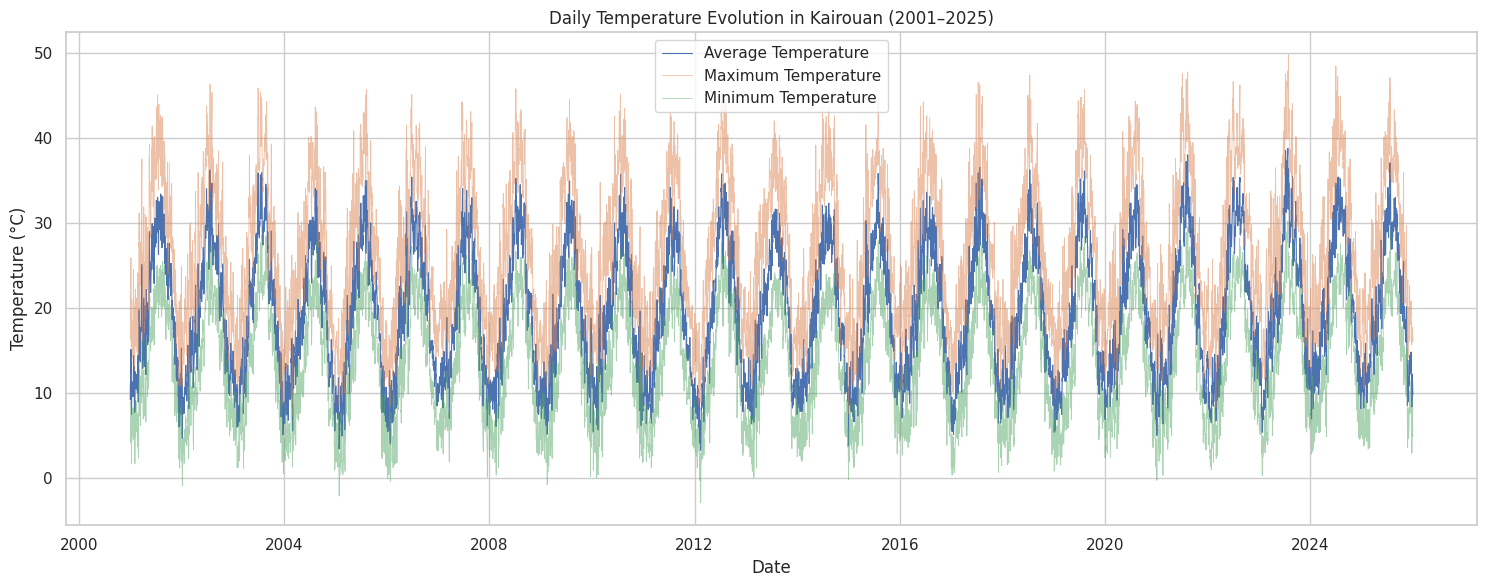

In [16]:
plt.figure(figsize=(15, 6))

plt.plot(df.index, df["T2M"],
         label="Average Temperature",
         linewidth=0.8)

plt.plot(df.index, df["T2M_MAX"],
         label="Maximum Temperature",
         alpha=0.5,
         linewidth=0.6)

plt.plot(df.index, df["T2M_MIN"],
         label="Minimum Temperature",
         alpha=0.5,
         linewidth=0.6)

plt.title("Daily Temperature Evolution in Kairouan (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

## 4.4 Precipitation Analysis

Precipitation is one of the most important variables in agricultural drought analysis.

The amount and distribution of rainfall directly influence soil water availability and agricultural conditions.

In this section, we analyze daily and monthly precipitation patterns to identify dry periods, rainfall variability, and seasonal differences.

Monthly precipitation will be calculated by aggregating daily precipitation values.

In [ ]:
# Calculate Monthly Precipitation
monthly_rain = df["PRECTOTCORR"].resample("ME").sum()

# Plot Monthly Precipitation
plt.figure(figsize=(15, 6))

plt.plot(monthly_rain.index, monthly_rain.values,
         linewidth=0.8)

plt.title("Monthly Precipitation Evolution (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm/month)")
plt.tight_layout()
plt.show()

## 4.5 Seasonal Precipitation Analysis

Rainfall distribution varies throughout the year due to seasonal climatic conditions.

Analyzing monthly rainfall patterns helps identify the wettest and driest periods in Kairouan.

This analysis is important for understanding the seasonal distribution of water availability and identifying periods that may require particular attention in agricultural water management.

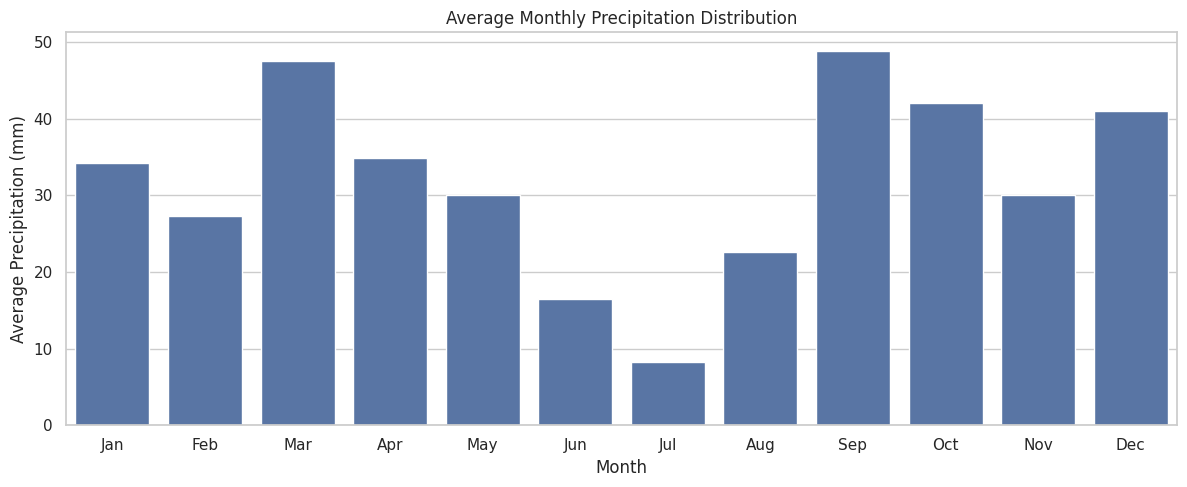

In [17]:
# Calculate Average Monthly Precipitation
monthly_avg_rain = df["PRECTOTCORR"].resample("ME").sum()
monthly_avg_rain = monthly_avg_rain.groupby(
    monthly_avg_rain.index.month
).mean()

# Plot Average Monthly Rainfall
plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_avg_rain.index,
    y=monthly_avg_rain.values
)

plt.title("Average Monthly Precipitation Distribution")
plt.xlabel("Month")
plt.ylabel("Average Precipitation (mm)")
plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

## 4.6 Relative Humidity Analysis

Relative humidity represents the amount of water vapor present in the atmosphere compared with the maximum amount it can hold at a given temperature.

It is an important environmental variable because it influences evapotranspiration and atmospheric water demand.

In this section, we analyze the evolution and distribution of relative humidity in Kairouan.

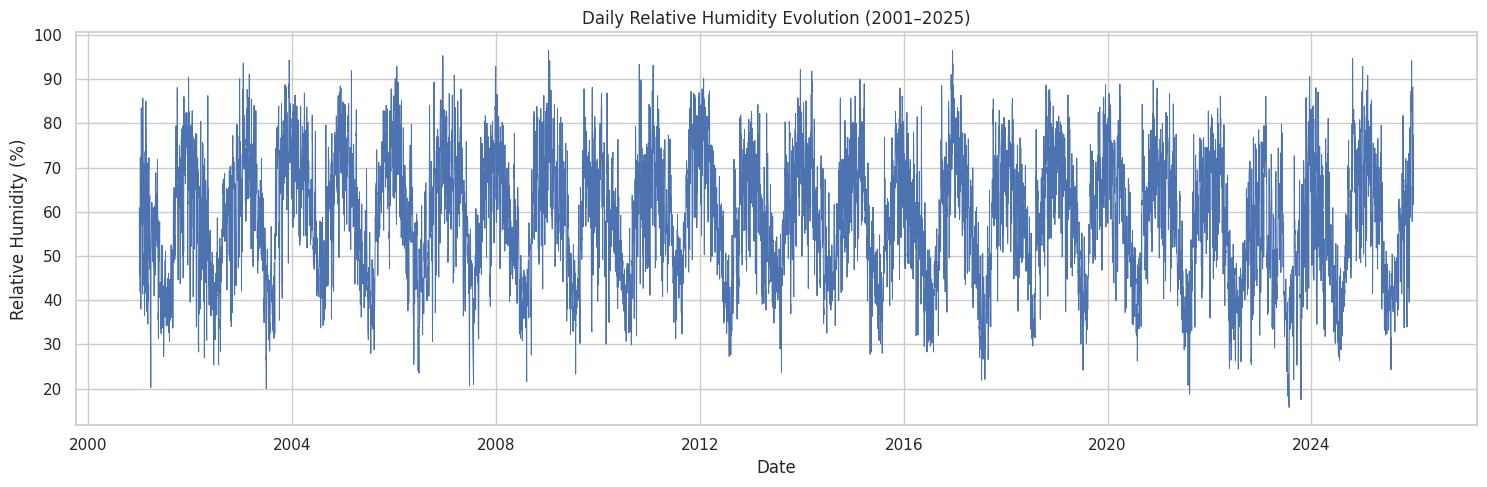

In [18]:
plt.figure(figsize=(15, 5))

plt.plot(df.index, df["RH2M"],
         linewidth=0.7)

plt.title("Daily Relative Humidity Evolution (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()

## 4.7 Wind Speed Analysis

Wind speed is another meteorological variable that can influence agricultural water loss through its effect on evapotranspiration.

Higher wind speeds can increase the rate of water transfer from soil and plant surfaces to the atmosphere.

This section examines the temporal variation and statistical distribution of wind speed in the study area.

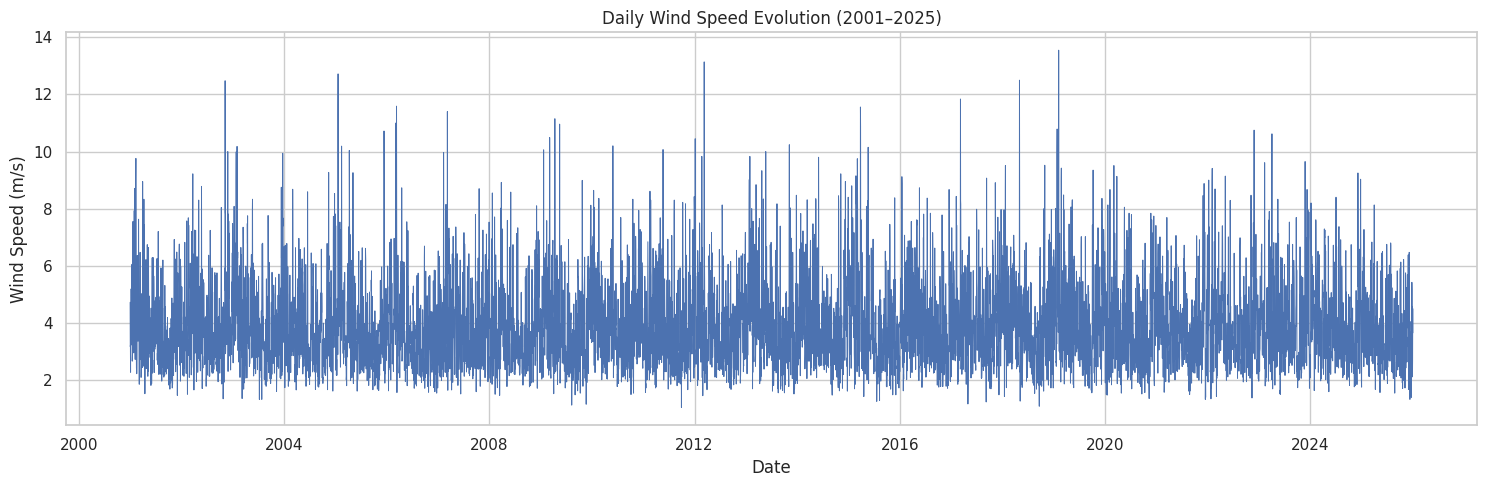

In [19]:
plt.figure(figsize=(15, 5))

plt.plot(df.index, df["WS10M"],
         linewidth=0.7)

plt.title("Daily Wind Speed Evolution (2001–2025)")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")

plt.tight_layout()
plt.show()

## 4.8 Distribution Analysis

Distribution analysis helps us understand the statistical characteristics of meteorological variables.

Histograms and boxplots are used to examine the frequency, spread, central tendency, and potential extreme values of the collected observations.

This analysis can also help identify skewed distributions and possible outliers that may require further investigation.

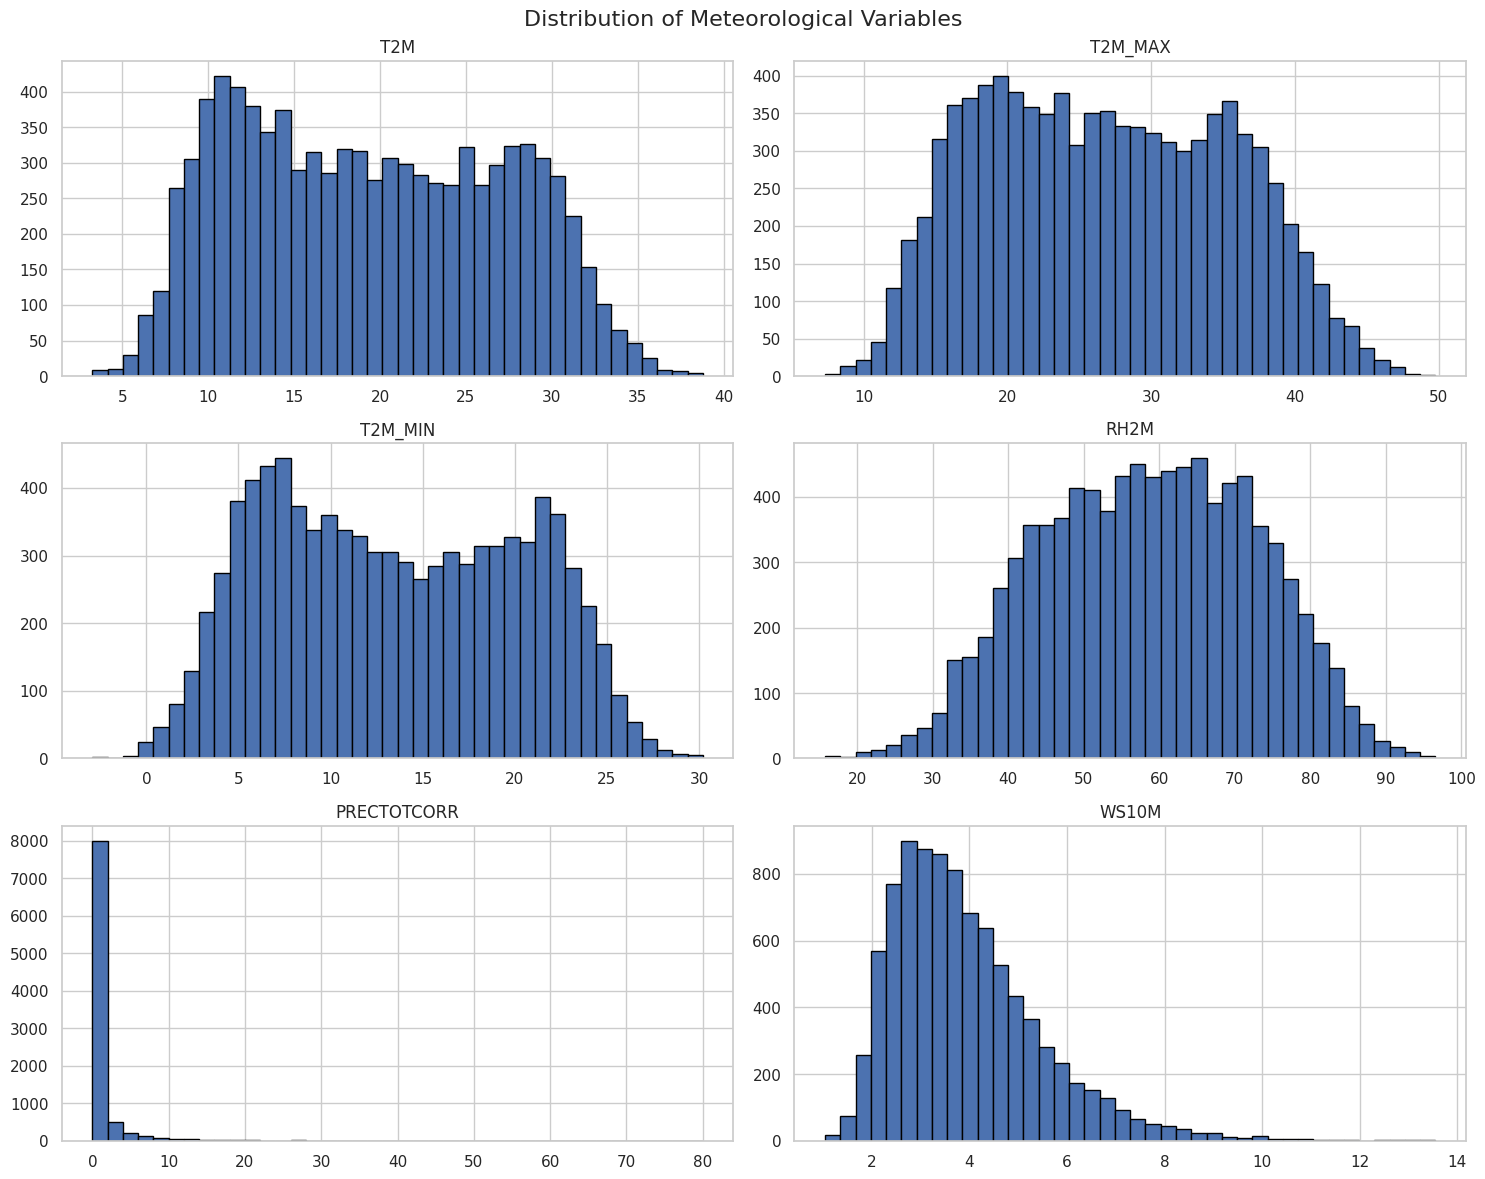

In [20]:
variables = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "PRECTOTCORR",
    "WS10M"
]

df[variables].hist(
    figsize=(15, 12),
    bins=40,
    edgecolor="black"
)

plt.suptitle("Distribution of Meteorological Variables",
             fontsize=16)

plt.tight_layout()
plt.show()

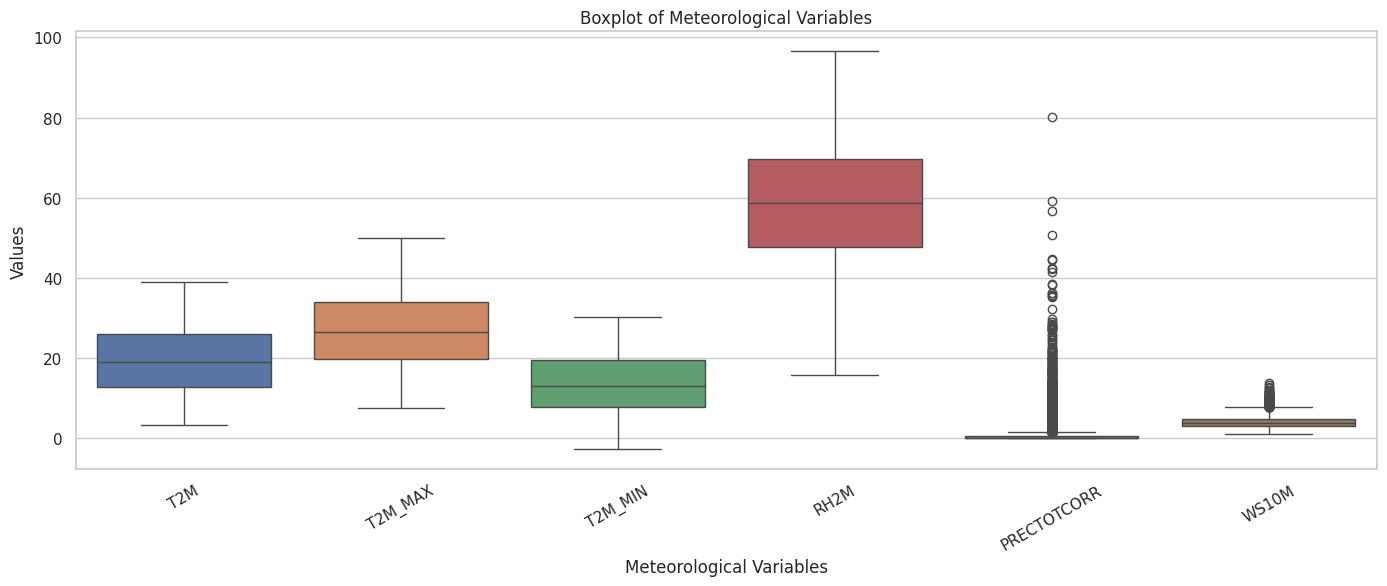

In [21]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[variables])

plt.title("Boxplot of Meteorological Variables")
plt.xlabel("Meteorological Variables")
plt.ylabel("Values")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4.9 Correlation Analysis

Correlation analysis is used to investigate the statistical relationships between meteorological variables.

A correlation matrix measures the strength and direction of linear relationships between numerical variables.

The Pearson correlation coefficient ranges from -1 to +1:

- +1 indicates a perfect positive linear relationship.
- -1 indicates a perfect negative linear relationship.
- 0 indicates no linear correlation.

This analysis helps identify relationships between temperature, precipitation, relative humidity, and wind speed.

In [ ]:
# Calculate Correlation Matrix
correlation_matrix = df[variables].corr()

# Plot Correlation Heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Meteorological Variables")
plt.tight_layout()
plt.show()

## 4.10 Monthly Temperature Patterns

Seasonal temperature variations are important for understanding the climatic characteristics of the study area.

A monthly temperature analysis allows us to compare average temperatures across different months and identify the hottest and coolest periods of the year.

This information can help characterize seasonal environmental conditions and support subsequent drought-related analysis.

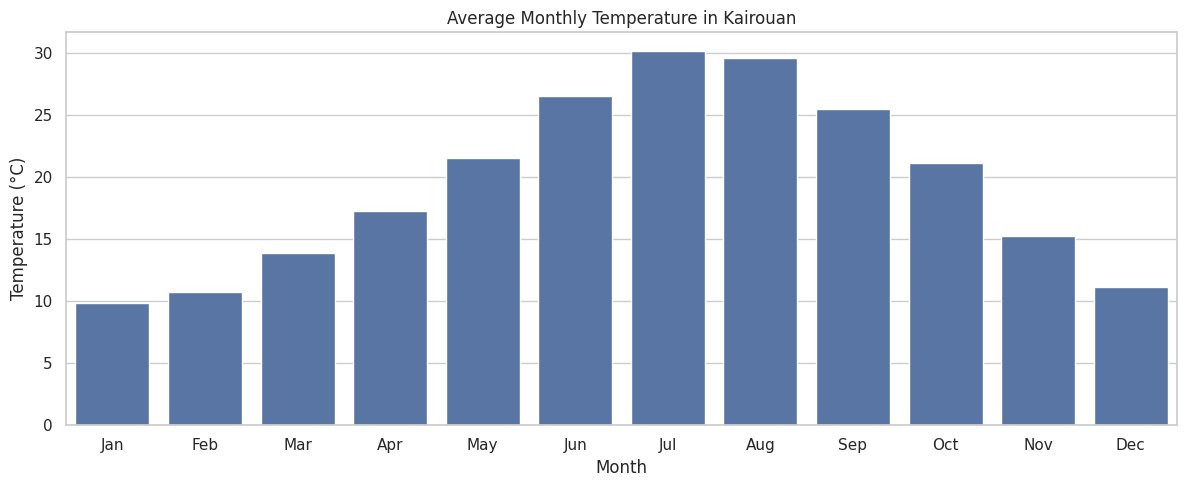

In [22]:
# Calculate Average Temperature by Month
monthly_temp = df["T2M"].groupby(df.index.month).mean()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_temp.index,
    y=monthly_temp.values
)

plt.title("Average Monthly Temperature in Kairouan")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

In [9]:
from google.colab import files

files.download("data/raw/kairouan_weather.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>